In [2]:
import pandas as pd 
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

import joblib

In [3]:
import warnings
warnings.filterwarnings("ignore")

In [4]:
sns.set_style("whitegrid")

In [5]:
df = pd.read_csv("medical_insurance.csv")

In [6]:
df

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
2767,47,female,45.320,1,no,southeast,8569.86180
2768,21,female,34.600,0,no,southwest,2020.17700
2769,19,male,26.030,1,yes,northwest,16450.89470
2770,23,male,18.715,0,no,northwest,21595.38229


In [7]:
df.describe()

,age,bmi,children,charges
count,2772.000000,2772.000000,2772.000000,2772.000000
mean,39.109668,30.701349,1.101732,13261.369959
std,14.081459,6.129449,1.214806,12151.768945
min,18.000000,15.960000,0.000000,1121.873900
25%,26.000000,26.220000,0.000000,4687.797000
50%,39.000000,30.447500,1.000000,9333.014350
75%,51.000000,34.770000,2.000000,16577.779500
max,64.000000,53.130000,5.000000,63770.428010


In [8]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [9]:
df[df.duplicated()].sort_values(by="charges")

,age,sex,bmi,children,smoker,region,charges
1373,18,male,23.210,0,no,southeast,1121.87390
2759,18,male,23.210,0,no,southeast,1121.87390
2326,18,male,23.210,0,no,southeast,1121.87390
2194,18,male,30.140,0,no,southeast,1131.50660
1353,18,male,33.330,0,no,southeast,1135.94070
...,...,...,...,...,...,...,...
2205,33,female,35.530,0,yes,northwest,55135.40209
1963,31,female,38.095,1,yes,northeast,58571.07448
2616,52,male,34.485,3,yes,northwest,60021.39897
2686,45,male,30.360,0,yes,southeast,62592.87309


In [10]:
dup_counts = df.groupby(list(df.columns)).size().reset_index(name = "count")
dup_counts["count"].value_counts().sort_index()

count
2    1288
4      49
Name: count, dtype: int64

In [11]:
df = df.drop_duplicates().reset_index(drop=True)

In [12]:
df.duplicated().sum()

np.int64(0)

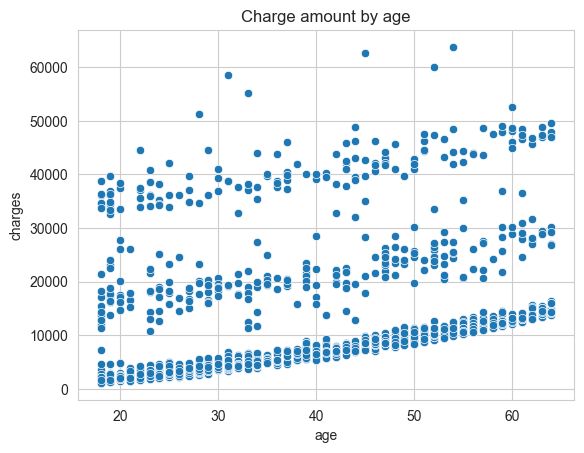

In [13]:
sns.scatterplot(data=df, x="age", y="charges")
plt.title("Charge amount by age")
plt.show()

Text(0, 0.5, 'Insurance Amount')

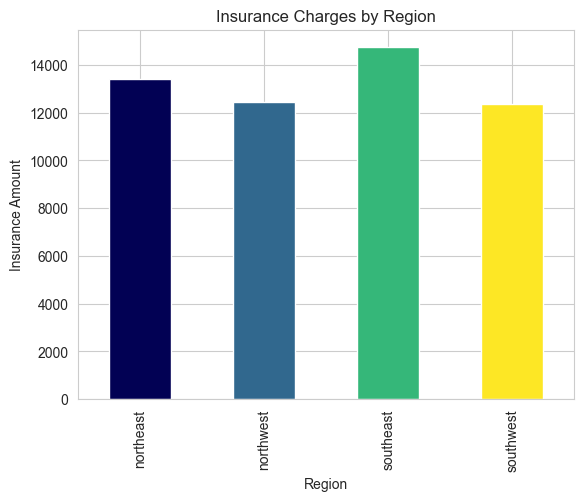

In [14]:
charges_by_region = df.groupby("region")["charges"].mean()
charges_by_region.plot(kind="bar", color=["#020154", "#31688e", "#35b779", "#fde725"])
plt.title("Insurance Charges by Region")
plt.xlabel("Region")
plt.ylabel("Insurance Amount")

In [15]:
for col in ["sex", "smoker", "region"]:
    print(f"----{col}----")
    print(df[col].value_counts())
    print(df[col].value_counts(normalize=True).round(3))

----sex----
sex
male      675
female    662
Name: count, dtype: int64
sex
male      0.505
female    0.495
Name: proportion, dtype: float64
----smoker----
smoker
no     1063
yes     274
Name: count, dtype: int64
smoker
no     0.795
yes    0.205
Name: proportion, dtype: float64
----region----
region
southeast    364
southwest    325
northwest    324
northeast    324
Name: count, dtype: int64
region
southeast    0.272
southwest    0.243
northwest    0.242
northeast    0.242
Name: proportion, dtype: float64


In [16]:
for col in ["age", "bmi", "children", "charges"]:
    print(f"{col}: skew= {df[col].skew():.3f}, kurtosis = {df[col].kurt():.3f}")

age: skew= 0.055, kurtosis = -1.244
bmi: skew= 0.284, kurtosis = -0.053
children: skew= 0.937, kurtosis = 0.201
charges: skew= 1.515, kurtosis = 1.604


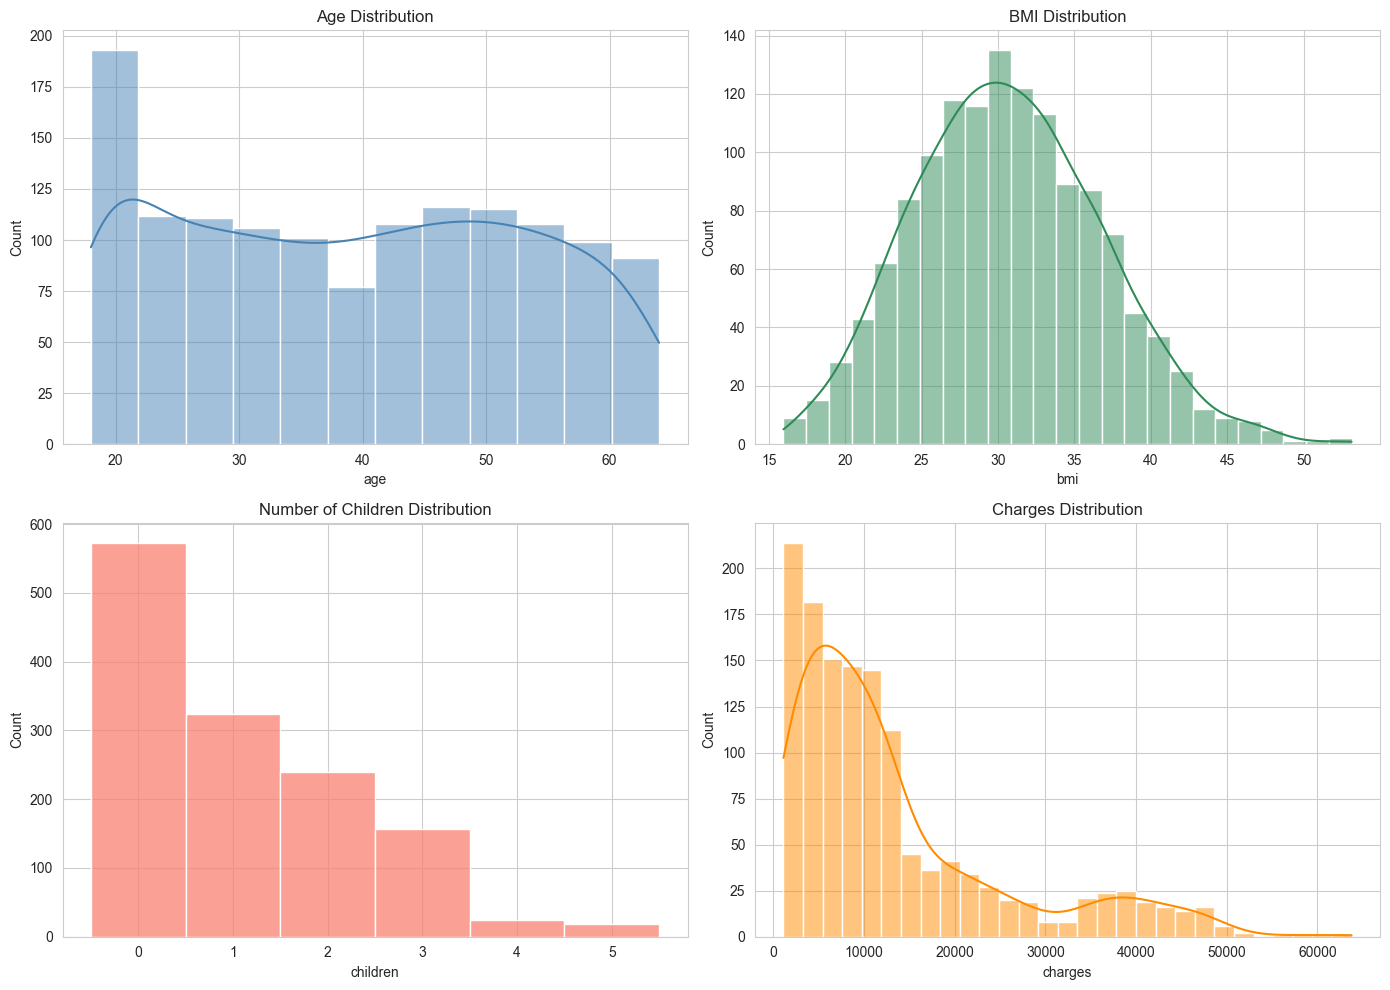

In [17]:
fig, axes = plt.subplots(2,2, figsize=(14,10))

sns.histplot(df["age"], kde= True, ax = axes[0,0], color = "steelblue")
axes[0,0].set_title("Age Distribution")

sns.histplot(df["bmi"], kde= True, ax = axes[0,1], color = "seagreen")
axes[0,1].set_title("BMI Distribution")

sns.histplot(df["children"], discrete= True, ax = axes[1,0], color = "salmon")
axes[1,0].set_title("Number of Children Distribution")

sns.histplot(df["charges"], kde= True, ax = axes[1,1], color = "darkorange")
axes[1,1].set_title("Charges Distribution")

plt.tight_layout()

plt.show()

In [18]:
for col in ["bmi", "charges"]:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    n_out = ((df[col] < lower) | (df[col] > upper)).sum()
    
    print(f"{col}: bounds = ({lower:.1f}, {upper:.1f}), outliers = {n_out} ({n_out/len(df[col]) * 100:.1f}%)")


bmi: bounds = (13.7, 47.3), outliers = 9 (0.7%)
charges: bounds = (-13120.7, 34524.8), outliers = 139 (10.4%)


In [19]:
df.groupby("smoker")["charges"].agg(["mean", "median", "std", "count"])

,mean,median,std,count
smoker,,,,
no,8440.660307,7345.72660,5992.973800,1063
yes,32050.231832,34456.34845,11541.547176,274


In [20]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [21]:
def bmi_category(bmi):
    if bmi < 18.5:
        return "underweight"
    elif bmi < 25:
        return "normal"
    elif bmi < 30:
        return "overweight"
    else:
        return "obese"

In [22]:
df["bmi_category"] = df["bmi"].apply(bmi_category)

In [23]:
df.head()

,age,sex,bmi,children,smoker,region,charges,bmi_category
0,19,female,27.900,0,yes,southwest,16884.92400,overweight
1,18,male,33.770,1,no,southeast,1725.55230,obese
2,28,male,33.000,3,no,southeast,4449.46200,obese
3,33,male,22.705,0,no,northwest,21984.47061,normal
4,32,male,28.880,0,no,northwest,3866.85520,overweight


In [24]:
df["bmi_category"].value_counts()

bmi_category
obese          706
overweight     386
normal         225
underweight     20
Name: count, dtype: int64

In [25]:
df.groupby("bmi_category")["charges"].mean().sort_values(ascending=False).round(2)

bmi_category
obese          15572.04
overweight     10987.51
normal         10409.34
underweight     8852.20
Name: charges, dtype: float64

In [26]:
df["log_charges"] = np.log1p(df["charges"])

In [27]:
for col in ["bmi", "charges", "log_charges"]:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    n_out = ((df[col] < lower) | (df[col] > upper)).sum()
    
    print(f"{col}: bounds = ({lower:.1f}, {upper:.1f}), outliers = {n_out} ({n_out/len(df[col]) * 100:.1f}%)")

bmi: bounds = (13.7, 47.3), outliers = 9 (0.7%)
charges: bounds = (-13120.7, 34524.8), outliers = 139 (10.4%)
log_charges: bounds = (6.6, 11.6), outliers = 0 (0.0%)


In [28]:
df["charges"].skew()


np.float64(1.5153909108403483)

In [29]:
df["log_charges"].skew()

np.float64(-0.08955835073325419)

In [30]:
df.head()

,age,sex,bmi,children,smoker,region,charges,bmi_category,log_charges
0,19,female,27.900,0,yes,southwest,16884.92400,overweight,9.734236
1,18,male,33.770,1,no,southeast,1725.55230,obese,7.453882
2,28,male,33.000,3,no,southeast,4449.46200,obese,8.400763
3,33,male,22.705,0,no,northwest,21984.47061,normal,9.998137
4,32,male,28.880,0,no,northwest,3866.85520,overweight,8.260455


In [31]:
df_model = pd.get_dummies(
    df,
    columns = ["sex", "smoker", "region", "bmi_category"],
    drop_first = True
)

print(df_model.columns.to_list())

['age', 'bmi', 'children', 'charges', 'log_charges', 'sex_male', 'smoker_yes', 'region_northwest', 'region_southeast', 'region_southwest', 'bmi_category_obese', 'bmi_category_overweight', 'bmi_category_underweight']


In [33]:
df_model.head()

,age,bmi,children,charges,log_charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest,bmi_category_obese,bmi_category_overweight,bmi_category_underweight
0,19,27.900,0,16884.92400,9.734236,False,True,False,False,True,False,True,False
1,18,33.770,1,1725.55230,7.453882,True,False,False,True,False,True,False,False
2,28,33.000,3,4449.46200,8.400763,True,False,False,True,False,True,False,False
3,33,22.705,0,21984.47061,9.998137,True,False,True,False,False,False,False,False
4,32,28.880,0,3866.85520,8.260455,True,False,True,False,False,False,True,False


In [34]:
feature_cols = [c for c in df_model.columns if c not in ["charges", "log_charges"]]

X = df_model[feature_cols]

y = df_model["log_charges"]

In [35]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

In [37]:
y_test_real = np.expm1(y_test)

candidate_models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=300, max_depth=6, n_jobs = -1),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=300, max_depth=3, learning_rate=0.05)
}

trained_models = {}
metrics_rows = []

for name, model in candidate_models.items():

    model.fit(X_train, y_train)
    y_pred_log = model.predict(X_test)
    y_pred = np.expm1(y_pred_log)

    r2 = r2_score(y_test_real, y_pred)
    mae = mean_absolute_error(y_test_real, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test_real, y_pred))

    trained_models[name] = model
    metrics_rows.append({
        "Model": name, 
        "R2": r2,
        "MAE": mae,
        "RMSE": rmse
    })

    print(f"{name} -> R2: {r2:.4f} - MAE: {mae:.2f} - RMSE: {rmse:.2f}")

Linear Regression -> R2: 0.5286 - MAE: 3746.47 - RMSE: 7836.30
Random Forest -> R2: 0.8580 - MAE: 1913.17 - RMSE: 4301.67
Gradient Boosting -> R2: 0.8464 - MAE: 2066.11 - RMSE: 4472.64


In [39]:
print(trained_models, "\n")
print(metrics_rows)

{'Linear Regression': LinearRegression(), 'Random Forest': RandomForestRegressor(max_depth=6, n_estimators=300, n_jobs=-1), 'Gradient Boosting': GradientBoostingRegressor(learning_rate=0.05, n_estimators=300)} 

[{'Model': 'Linear Regression', 'R2': 0.5286061923964405, 'MAE': 3746.4723003699855, 'RMSE': np.float64(7836.295394162403)}, {'Model': 'Random Forest', 'R2': 0.8579514320553581, 'MAE': 1913.167587004808, 'RMSE': np.float64(4301.671993268326)}, {'Model': 'Gradient Boosting', 'R2': 0.846436063162522, 'MAE': 2066.113121068053, 'RMSE': np.float64(4472.635234257508)}]


In [42]:
results = pd.DataFrame(metrics_rows).sort_values("R2", ascending = False).reset_index(drop=True)

In [43]:
results.round(4)

,Model,R2,MAE,RMSE
0,Random Forest,0.8580,1913.1676,4301.6720
1,Gradient Boosting,0.8464,2066.1131,4472.6352
2,Linear Regression,0.5286,3746.4723,7836.2954


In [51]:
best_model_name = results.loc[0, "Model"]
best_model = trained_models[best_model_name]

In [53]:
best_model_name

'Random Forest'

In [55]:
best_model

,n_estimators,300
,criterion,'squared_error'
,max_depth,6
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [56]:
joblib.dump(best_model, "insurance_model.pkl")
joblib.dump(feature_cols, "model_features.pkl")
joblib.dump(best_model_name, "model_name.pkl")

['model_name.pkl']